# The Tetrarchy: College Access and Economic Mobility
## Chart notebook for the seven-slide mock-up and critique deck

**Run order:** Make sure `college_mobility.csv` is beside this notebook. It should have the 2 table 1 columns `trend_parq1` and `trend_bottom40` joined with table 2. Final shape after filtering should be (2199, 87)


| Code-cell label | Slide | Question / task | Output |
|---|---|---|---|
| SETUP-1 and SETUP-2 | All | Load, validate, define units and helpers | Data summary |
| DEFINE-Q1 through DEFINE-Q4 | 3–6 | Define four reusable chart designs | No figure yet |
| S2-A | 2, About | Q1A: compare low-income access by sector | `s2a_access.png` |
| S2-B | 2, About | Q2A: access–success relationship | `s2b_mobility.png` |
| S2-C | 2, About | Q4A: access changes by sector | `s2c_change.png` |
| S3-A | 3 | Q1A: distribution of access by sector | `s3a_access_sector.png` |
| S3-B | 3 | Q1B: distribution of the top-minus-bottom gap by tier | `s3b_gap_tier.png` |
| S4 | 4 | Q2A + Q2B: scatter and ranked results | `s4_mobility.png`, `s4_ranked_results.csv` |
| S5 | 5 | Q3A + Q3B: earnings profiles and computed gaps | `s5_profiles.png`, `s5_rank_gaps.csv` |
| S6-A | 6 | Q4A: distribution of bottom-20% access changes | `s6a_change_all.png` |
| S6-B | 6 | Q4B: identify colleges meeting the opposite-change condition | `s6b_matching_colleges.csv` |
| S6-C | 6, alternate state in ZIP | Q4A + Q4B: same chart after filtering | `s6c_change_subset.png` |
| WIDGETS | 3–6 | Try the planned interactions | Optional live controls |

## SETUP-1 — All slides — Load the final joined dataset

In [1]:
# SETUP-1 | All slides | Input only; no chart
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("college_mobility.csv")
ASSET_DIR = Path("assets")
ASSET_DIR.mkdir(exist_ok=True)
table3 = pd.read_csv(DATA_FILE)
assert table3["super_opeid"].is_unique, "Each college/group must appear once."
assert table3["super_opeid"].gt(0).all(), "Remove special negative IDs."
print("Final source dataset:", table3.shape)

data = table3.copy()
SECTORS = {1: "Public", 2: "Private nonprofit", 3: "For-profit"}
COLORS = {"Public": "#256b80", "Private nonprofit": "#737d88", "For-profit": "#b0894e"}
TIER_LABELS = {1:"Ivy Plus", 2:"Other elite", 3:"Highly selective public",
 4:"Highly selective private", 5:"Selective public", 6:"Selective private",
 7:"Nonselective 4-year public", 8:"Nonselective 4-year private",
 9:"Two-year nonprofit/public", 10:"Four-year for-profit",
 11:"Two-year for-profit", 12:"Less than two years"}
data["sector"] = data["type"].map(SECTORS)
data["access_pct"] = 100 * data["par_q1"]
data["success_pct"] = 100 * data["kq5_cond_parq1"]
data["mobility_pct"] = 100 * data["mr_kq5_pq1"]
data["representation_gap_pp"] = 100 * (data["par_q5"] - data["par_q1"])
data["earnings_gap_rank_points"] = 100 * (data["k_rank_cond_parq5"] - data["k_rank_cond_parq1"])
# trend_parq1 and trend_bottom40 already use percentage points. Do not multiply them by 100.
print("Access–success correlation:", round(data["access_pct"].corr(data["success_pct"]), 3))

FileNotFoundError: [Errno 2] No such file or directory: 'college_mobility.csv'

## SETUP-2 — All slides — Common style and export helper

Access, conditional success, and overall mobility are different measures. Overall mobility is the share of **all students** who start in the bottom parental-income fifth and reach the top earnings fifth. It equals access × conditional success. Source ranks use 0–1 scales; the charts show them on 0–100 scales.

Baseline outcomes mainly describe the 1980–1982 birth cohorts, supplemented by 1983–1984 when needed. Adult individual earnings are measured in 2014. Access changes compare the 1980 and 1991 **birth cohorts**. These are historical associations, not estimates of colleges' causal effects.

In [2]:
# SETUP-2 | All slides | Formatting and export helpers; no chart
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
 "axes.spines.top": False, "axes.spines.right": False,
 "axes.edgecolor": "#9aa1a7", "text.color": "#20313b",
 "axes.labelcolor": "#20313b", "savefig.facecolor": "white"})

def new_axes(size=(9, 4.7)):
    fig, ax = plt.subplots(figsize=size, layout="constrained")
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#e5e9ec", linewidth=0.7)
    return fig, ax

def finish(fig, filename):
    # Save before show/close so the exported file contains the chart.
    fig.savefig(ASSET_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def no_matches(fig, ax):
    ax.clear()
    ax.axis("off")
    ax.text(0.5, 0.5, "No colleges match these settings. Try a different filter.",
            ha="center", va="center", transform=ax.transAxes, wrap=True)
    return fig

## DEFINE-Q1 — Slide 3 — Access and representation

**Q1A / Characterize Distribution:** compare bottom-20% shares across sectors.

**Q1B / Compute Derived Value:** calculate each college's top-parent-fifth share minus bottom-parent-fifth share, then compare distributions across tiers.

**Encoding:** horizontal position shows the percentage or percentage-point gap. The box shows the middle 50%, the line shows the median, and the points show outliers. The proposed dropdowns change the measure and grouping. Slide 3 shows two settings of this one design.

In [3]:
# DEFINE-Q1 | Slide 3; reused on Slide 2 | Defines a function; no chart yet
def plot_access(df, measure="Access", group_by="Sector", size=(8.1, 4.7), compact=False):
    fig, ax = new_axes(size)
    column = "access_pct" if measure == "Access" else "representation_gap_pp"
    if group_by == "Sector":
        groups = [(label, df.loc[df["sector"].eq(label), column].dropna())
                  for label in SECTORS.values()]
        fills = [COLORS[label] for label, _ in groups]
    else:
        groups = [(TIER_LABELS.get(int(tier), str(tier)), group[column].dropna())
                  for tier, group in df.groupby("tier", sort=True)]
        fills = ["#95a9b3"] * len(groups)
    present = [(label, values, fill) for (label, values), fill in zip(groups, fills) if len(values)]
    if not present: return no_matches(fig, ax)
    boxes = ax.boxplot([values for _, values, _ in present], vert=False, patch_artist=True,
        medianprops={"color":"#16252e", "linewidth":2},
        flierprops={"marker":"o", "markersize":2.5, "alpha":0.35,
                    "markeredgecolor":"#6d7980", "markerfacecolor":"none"})
    for patch, (_, _, color) in zip(boxes["boxes"], present): patch.set_facecolor(color)
    ax.set_yticks(range(1, len(present)+1), [label for label, _, _ in present])
    ax.invert_yaxis()
    ax.tick_params(axis="y", labelsize=10 if group_by == "Tier" else 12)
    if measure == "Access":
        ax.set_xlim(0, 65)
        ax.set_xlabel("Students from bottom-20% families (%)")
    else:
        ax.set_xlim(-65, 100)
        ax.axvline(0, color="#48545c", linewidth=1)
        ax.set_xlabel("Top-20% share minus bottom-20% share (pp)")
    if compact:
        ax.tick_params(labelsize=10)
        ax.set_xlabel("Bottom-20% student share (%)" if measure == "Access" else "Top-minus-bottom share (pp)")
    return fig

## DEFINE-Q2 — Slide 4 — Access, success, and overall mobility

**Q2A / Correlate:** examine access and conditional success at the same colleges.

**Q2B / Find Extremum:** identify the highest overall mobility rates within the selected tier. A small ranked **results table** identifies the colleges; it is not an additional chart.

The tier filter and minimum-access slider affect the scatter and the ranking together. Ringed points are the colleges listed in the results table. The table ranks the filtered comparison group, so increasing the minimum access changes its scope.

In [4]:
# DEFINE-Q2 | Slide 4; reused on Slide 2 | Defines functions; no chart yet
def mobility_subset(df, tier="All", min_access=0):
    g = df.copy()
    if tier != "All": g = g.loc[g["tier"].eq(tier)]
    return g.loc[g["access_pct"].ge(min_access)].dropna(subset=["access_pct","success_pct","mobility_pct"])

def mobility_results(df, tier="All", min_access=0, top_n=3):
    return mobility_subset(df, tier, min_access).nlargest(top_n, "mobility_pct")

def plot_mobility(df, tier="All", min_access=0, top_n=3, size=(8.3, 4.8), compact=False):
    fig, ax = new_axes(size)
    g = mobility_subset(df, tier, min_access)
    if g.empty: return no_matches(fig, ax)
    for label in SECTORS.values():
        sector = g.loc[g["sector"].eq(label)]
        if len(sector):
            ax.scatter(sector["access_pct"], sector["success_pct"], s=22 if not compact else 13,
                color=COLORS[label], alpha=0.5, edgecolors="none", label=label)
    if top_n:
        top = mobility_results(df, tier, min_access, top_n)
        ax.scatter(top["access_pct"], top["success_pct"], s=115, facecolors="none",
                   edgecolors="#17232b", linewidths=1.5, label="Highest overall mobility")
    ax.set(xlim=(0,65), ylim=(0,100), xlabel="Students from bottom-20% families (%)",
           ylabel="Reach top earnings fifth, among those students (%)")
    ax.grid(axis="y", color="#e5e9ec", linewidth=0.7)
    ax.legend(fontsize=9 if compact else 10, frameon=False, loc="upper right")
    if compact:
        ax.tick_params(labelsize=10)
        ax.set_xlabel("Bottom-20% student share (%)")
        ax.set_ylabel("Conditional success (%)")
    return fig

## DEFINE-Q3 — Slide 5 — Family background within colleges

**Q3A / Retrieve Value:** read mean adult earnings ranks for each of five parental-income quintiles.

**Q3B / Compute Derived Value:** subtract the bottom-parent-group mean rank from the top-parent-group mean rank. The result uses **earnings percentile-rank points**, not dollars or percent growth.

The college selector changes both the profiles and the small gap table. Lines connect ordered income groups; they do not show change over time. The default three colleges are illustrative choices, not a representative sample.

In [5]:
# DEFINE-Q3 | Slide 5 | Defines a function; no chart yet
DEFAULT_COLLEGES = [3745, 1140, 129]  # UVA, Cal State LA, Harvard

def plot_profiles(df, college_ids=DEFAULT_COLLEGES, size=(9.2, 4.8)):
    fig, ax = new_axes(size)
    columns = [f"k_rank_cond_parq{i}" for i in range(1,6)]
    g = df.set_index("super_opeid").reindex(list(college_ids)[:3]).dropna(subset=["name"])
    if g.empty: return no_matches(fig, ax)
    colors = ["#216b81", "#9a6c35", "#657280"]
    markers = ["o", "s", "^"]
    for (college_id, row), color, marker in zip(g.iterrows(), colors, markers):
        label = row["name"].title()
        ax.plot(range(1,6), row[columns].to_numpy(dtype=float)*100, marker=marker,
                linewidth=2, color=color, label=label)
    ax.set(xticks=range(1,6), xticklabels=["Bottom 20%","20–40%","40–60%","60–80%","Top 20%"],
           ylim=(0,100), xlabel="Parental-income group", ylabel="Mean adult earnings percentile rank")
    ax.grid(axis="y", color="#e5e9ec", linewidth=0.7)
    ax.legend(fontsize=10, loc="lower left", frameon=False)
    return fig

## DEFINE-Q4 — Slide 6 — Changes in access across birth cohorts

**Q4A / Characterize Distribution:** compare changes in bottom-20% access across sectors.

**Q4B / Filter:** select colleges with `trend_bottom40 > 0` and `trend_parq1 < 0`. The full results table identifies all matching colleges. The checkbox can apply this condition to the box plot. The deck labels its default plot and the preview of the filtered results as different states.

In [6]:
# DEFINE-Q4 | Slide 6; reused on Slide 2 | Defines functions; no chart yet
def opposite_change_matches(df):
    return df.loc[df["trend_bottom40"].gt(0) & df["trend_parq1"].lt(0)].copy()

def plot_change(df, income_group="Bottom 20%", opposite_only=False, size=(8.2, 4.7), compact=False):
    fig, ax = new_axes(size)
    g = opposite_change_matches(df) if opposite_only else df
    column = "trend_parq1" if income_group == "Bottom 20%" else "trend_bottom40"
    groups = [(label, g.loc[g["sector"].eq(label), column].dropna()) for label in SECTORS.values()]
    groups = [(label, values) for label, values in groups if len(values)]
    if not groups: return no_matches(fig, ax)
    boxes = ax.boxplot([values for _, values in groups], vert=False, patch_artist=True,
        medianprops={"color":"#16252e","linewidth":2},
        flierprops={"marker":"o","markersize":2.5,"alpha":0.35,
                    "markeredgecolor":"#6d7980","markerfacecolor":"none"})
    for patch, (label, _) in zip(boxes["boxes"], groups): patch.set_facecolor(COLORS[label])
    ax.set_yticks(range(1,len(groups)+1),[label for label,_ in groups]); ax.invert_yaxis()
    ax.axvline(0,color="#48545c",linestyle="--",linewidth=1)
    ax.set_xlim((-35,35) if income_group == "Bottom 20%" else (-90,60))
    ax.set_xlabel(f"Change in {income_group.lower()} share (percentage points)")
    if compact:
        ax.tick_params(labelsize=10)
        ax.set_xlabel("Bottom-20% access change (pp)" if income_group == "Bottom 20%" else "Bottom-40% access change (pp)")
    return fig

## S2-A — Slide 2, About — Static insight 1 — Q1A

**Chart:** distribution of bottom-20% access by sector. **Action:** Characterize Distribution. The printed medians support the headline. **Output:** `assets/s2a_access.png`.

Median access by sector (%):
sector
Public               12.9
Private nonprofit     5.9
For-profit           19.6


C:\Users\isaia\AppData\Local\Temp\ipykernel_20132\1015732811.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([values for _, values, _ in present], vert=False, patch_artist=True,


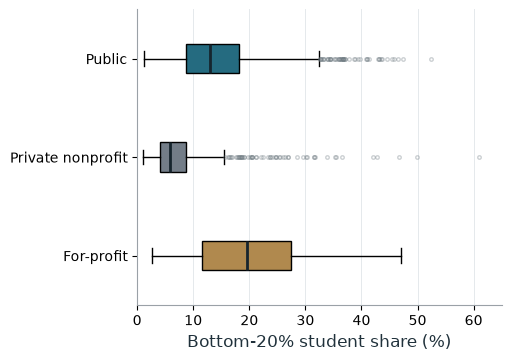

In [7]:
# S2-A | Slide 2, left panel | Q1A | Static About snapshot
access_medians = data.groupby("sector")["access_pct"].median().reindex(SECTORS.values())
print("Median access by sector (%):")
print(access_medians.round(1).to_string())
fig = plot_access(data, size=(5.0,3.5), compact=True)
finish(fig, "s2a_access.png")

## S2-B — Slide 2, About — Static insight 2 — Q2A

**Chart:** access versus conditional success for all colleges. **Action:** Correlate. Pearson's r describes an unweighted association across colleges. **Output:** `assets/s2b_mobility.png`.

Access–success correlation across colleges: r = -0.51


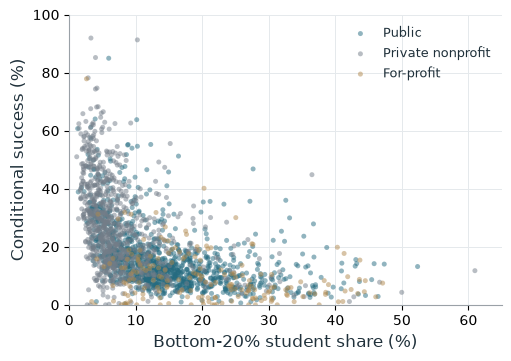

In [8]:
# S2-B | Slide 2, middle panel | Q2A | Static About snapshot
correlation = data["access_pct"].corr(data["success_pct"])
print(f"Access–success correlation across colleges: r = {correlation:.2f}")
fig = plot_mobility(data, top_n=0, size=(5.0,3.5), compact=True)
finish(fig, "s2b_mobility.png")

## S2-C — Slide 2, About — Static insight 3 — Q4A

**Chart:** bottom-20% access changes by sector. **Action:** Characterize Distribution. The sector medians support the comparison. **Output:** `assets/s2c_change.png`.

Median bottom-20% access change by sector (pp):
sector
Public               0.04
Private nonprofit   -0.20
For-profit           2.05


C:\Users\isaia\AppData\Local\Temp\ipykernel_20132\3555882911.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([values for _, values in groups], vert=False, patch_artist=True,


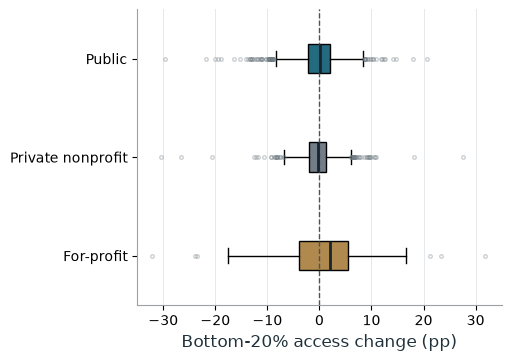

In [9]:
# S2-C | Slide 2, right panel | Q4A | Static About snapshot
change_medians = data.groupby("sector")["trend_parq1"].median().reindex(SECTORS.values())
print("Median bottom-20% access change by sector (pp):")
print(change_medians.round(2).to_string())
fig = plot_change(data, size=(5.0,3.5), compact=True)
finish(fig, "s2c_change.png")

## S3-A — Slide 3, State A — Q1A

**Settings:** Measure = Access; Group by = Sector. **Output:** `assets/s3a_access_sector.png`. This is the first setting of the Q1 chart.

C:\Users\isaia\AppData\Local\Temp\ipykernel_20132\1015732811.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([values for _, values, _ in present], vert=False, patch_artist=True,


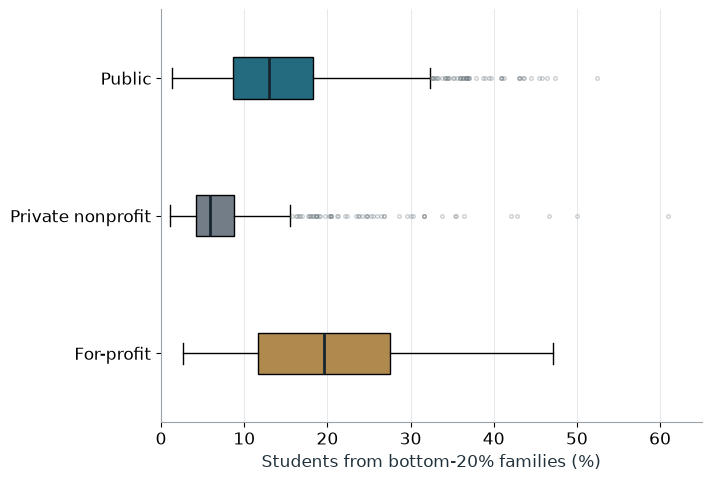

In [10]:
# S3-A | Slide 3, left example state | Q1A | Characterize Distribution
fig = plot_access(data, measure="Access", group_by="Sector", size=(7.0,4.7))
finish(fig, "s3a_access_sector.png")

## S3-B — Slide 3, State B — Q1B

**Settings:** Measure = Representation gap; Group by = Tier. **Output:** `assets/s3b_gap_tier.png`. Each box summarizes college-level differences. This is an alternate state of the same Q1 chart, not an additional required chart design.

C:\Users\isaia\AppData\Local\Temp\ipykernel_20132\1015732811.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([values for _, values, _ in present], vert=False, patch_artist=True,


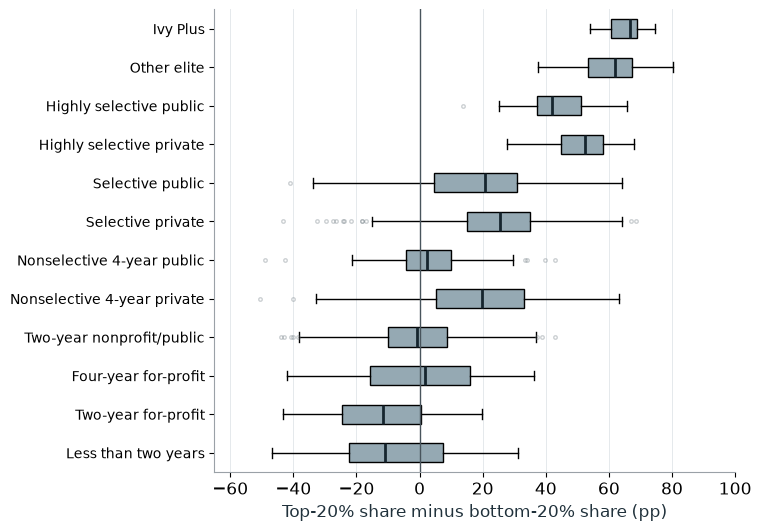

In [11]:
# S3-B | Slide 3, right example state | Q1B | Compute Derived Value
fig = plot_access(data, measure="Representation gap", group_by="Tier", size=(7.5,5.2))
finish(fig, "s3b_gap_tier.png")

## S4 — Slide 4 — Q2A and Q2B

**Settings:** Tier = Selective public (5); Minimum access = 0%; Top colleges = 3. **Chart:** `assets/s4_mobility.png`. **Results:** `assets/s4_ranked_results.csv`. Ringed points match the ranked results. Tier labels describe the source's historical classification.

Comparison group: Selective public; minimum access 0%


,College / group,Access (%),Success (%),Overall mobility (%)
0,CUNY Bernard M. Baruch College,27.63,46.82,12.94
1,City College Of New York - CUNY,32.55,36.02,11.72
2,CUNY Lehman College,36.71,27.88,10.24


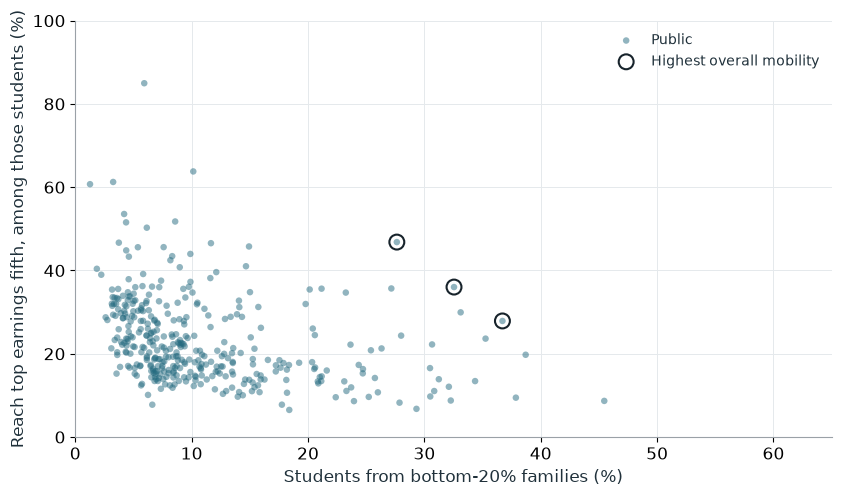

In [12]:
# S4 | Slide 4 | Q2A: Correlate; Q2B: Find Extremum
SELECTED_TIER = 5
MIN_ACCESS = 0
TOP_N = 3
top_colleges = mobility_results(data, SELECTED_TIER, MIN_ACCESS, TOP_N)
rank_table = top_colleges[["name","access_pct","success_pct","mobility_pct"]].copy()
rank_table.columns = ["College / group", "Access (%)", "Success (%)", "Overall mobility (%)"]
rank_table = rank_table.reset_index(drop=True).round(2)
print(f"Comparison group: {TIER_LABELS[SELECTED_TIER]}; minimum access {MIN_ACCESS}%")
display(rank_table)
rank_table.to_csv(ASSET_DIR / "s4_ranked_results.csv", index=False)
fig = plot_mobility(data, tier=SELECTED_TIER, min_access=MIN_ACCESS, top_n=TOP_N)
finish(fig, "s4_mobility.png")

## S5 — Slide 5 — Q3A and Q3B

**Chart:** mean earnings ranks by parental-income group at three selected colleges. **Calculated labels:** top-parent minus bottom-parent earnings-rank gap. **Outputs:** `assets/s5_profiles.png` and `assets/s5_rank_gaps.csv`.

,College / group,Earnings-rank gap (points)
0,University Of Virginia,7.15
1,"California State University, Los Angeles",3.87
2,Harvard University,6.90


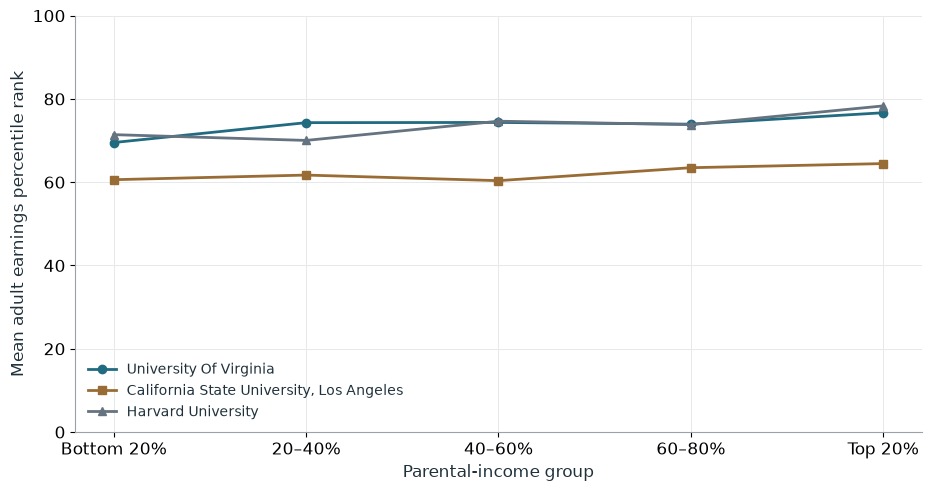

In [13]:
# S5 | Slide 5 | Q3A: Retrieve Value; Q3B: Compute Derived Value
selected_colleges = DEFAULT_COLLEGES
selected_rows = data.set_index("super_opeid").loc[selected_colleges]
gap_table = selected_rows[["name","earnings_gap_rank_points"]].copy().reset_index(drop=True)
gap_table.columns = ["College / group", "Earnings-rank gap (points)"]
gap_table["Earnings-rank gap (points)"] = gap_table["Earnings-rank gap (points)"].round(2)
display(gap_table)
gap_table.to_csv(ASSET_DIR / "s5_rank_gaps.csv", index=False)
fig = plot_profiles(data, selected_colleges)
finish(fig, "s5_profiles.png")

## S6-A — Slide 6, default chart — Q4A

**Settings:** Income group = Bottom 20%; Opposite changes only = OFF. **Output:** `assets/s6a_change_all.png`. This chart uses all 2,199 college/group observations.

C:\Users\isaia\AppData\Local\Temp\ipykernel_20132\3555882911.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([values for _, values in groups], vert=False, patch_artist=True,


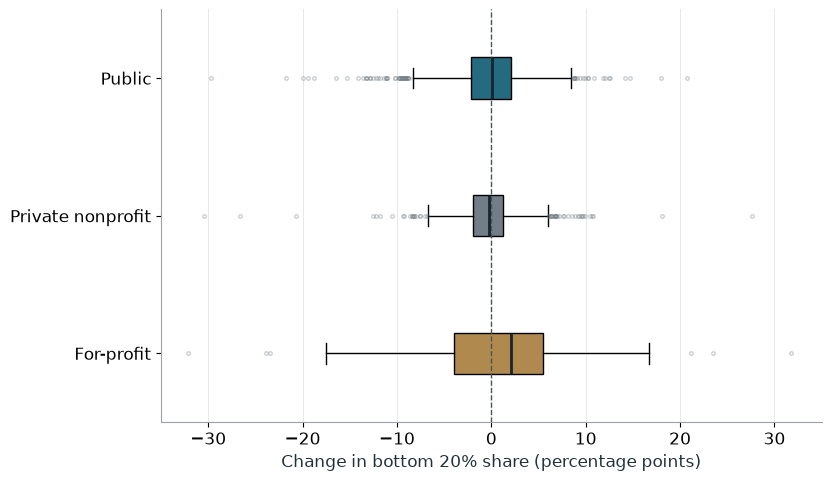

In [14]:
# S6-A | Slide 6, left chart | Q4A | Characterize Distribution
fig = plot_change(data, income_group="Bottom 20%", opposite_only=False)
finish(fig, "s6a_change_all.png")

## S6-B — Slide 6, filtered-results preview — Q4B

**Condition:** bottom-40% access change > 0 AND bottom-20% access change < 0. The CSV lists every matching college; the deck shows four examples with the largest bottom-40% increases. The deck explicitly labels this as the results state after checking the filter.

In [15]:
# S6-B | Slide 6, right results preview | Q4B | Filter
matching_colleges = opposite_change_matches(data).sort_values("trend_bottom40", ascending=False)
matches_table = matching_colleges[["name","trend_bottom40","trend_parq1"]].copy().reset_index(drop=True)
matches_table.columns = ["College / group", "Bottom-40% change (pp)", "Bottom-20% change (pp)"]
matches_table.iloc[:,1:] = matches_table.iloc[:,1:].round(2)
print(f"Colleges / groups meeting both conditions: {len(matches_table):,}")
display(matches_table)
matches_table.to_csv(ASSET_DIR / "s6b_matching_colleges.csv", index=False)

Colleges / groups meeting both conditions: 125


,College / group,Bottom-40% change (pp),Bottom-20% change (pp)
0,Florida Memorial University,54.42,-26.67
1,"Empire Beauty School of Portland, ME",11.41,-9.34
2,Newberry College,7.77,-0.04
3,Wilson Community College,7.46,-1.62
4,Beth Medrash Govoha Of America,6.80,-2.86
...,...,...,...
120,Vance - Granville Community College,0.09,-0.45
121,Boricua College,0.07,-4.60
122,Atlanta Technical College,0.07,-1.52
123,Massachusetts College Of Liberal Arts,0.05,-0.38


## S6-C — Slide 6 interaction example — Q4A and Q4B

**Settings:** Income group = Bottom 20%; Opposite changes only = ON. **Output:** `assets/s6c_change_subset.png`. This alternate chart image is included in the ZIP so you can replace the default screenshot during the critique if useful.

C:\Users\isaia\AppData\Local\Temp\ipykernel_20132\3555882911.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([values for _, values in groups], vert=False, patch_artist=True,


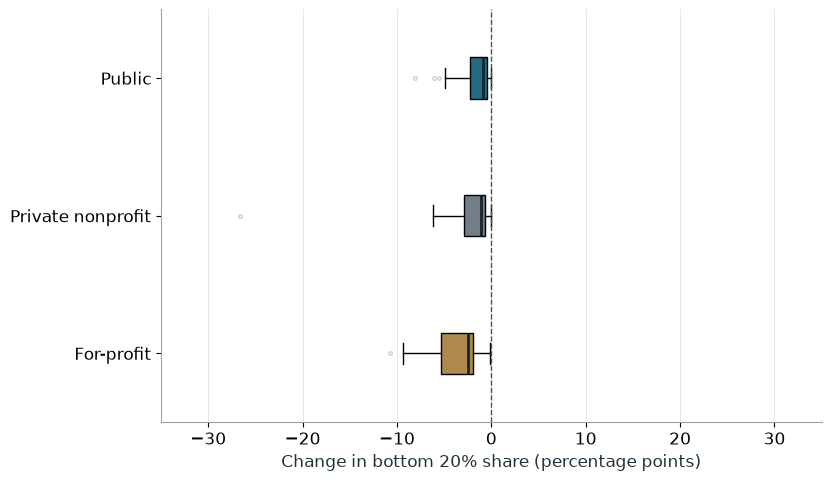

In [16]:
# S6-C | Slide 6, alternate filtered chart state | Q4A and Q4B
fig = plot_change(data, income_group="Bottom 20%", opposite_only=True)
finish(fig, "s6c_change_subset.png")

## WIDGETS — Proof of concept live controls corresponding to Slides 3–6

In [17]:
# WIDGETS | Slides 3–6 | Optional prototype; no slide image is exported here
import ipywidgets as widgets
from IPython.display import clear_output

def show_q1(measure, group_by):
    fig = plot_access(data, measure, group_by)
    plt.show(); plt.close(fig)

def show_q2(tier, min_access, top_n):
    g = mobility_results(data, tier, min_access, top_n)
    fig = plot_mobility(data, tier, min_access, top_n)
    plt.show(); plt.close(fig)
    display(g[["name","access_pct","success_pct","mobility_pct"]].reset_index(drop=True).round(2))

def show_q3(colleges):
    ids = list(colleges)[:3]
    if len(colleges)>3: print("Only the first three selected colleges are shown.")
    fig = plot_profiles(data, ids)
    plt.show(); plt.close(fig)
    display(data.loc[data.super_opeid.isin(ids),["name","earnings_gap_rank_points"]].round(2))

def show_q4(income_group, opposite_only):
    fig = plot_change(data, income_group, opposite_only)
    plt.show(); plt.close(fig)
    if opposite_only:
        display(opposite_change_matches(data)[["name","trend_bottom40","trend_parq1"]].reset_index(drop=True).round(2))

def panel(callback, controls):
    output = widgets.interactive_output(callback, controls)
    return widgets.VBox([*controls.values(), output])

college_options = [(row.name.title(), int(row.super_opeid)) for row in data.sort_values("name").itertuples()]
selected_first = [item for key in DEFAULT_COLLEGES for item in college_options if item[1] == key]
college_options = selected_first + [item for item in college_options if item[1] not in DEFAULT_COLLEGES]
pages = [
 panel(show_q1, {"measure": widgets.Dropdown(options=["Access","Representation gap"], description="Measure"),
                 "group_by": widgets.Dropdown(options=["Sector","Tier"], description="Group by")}),
 panel(show_q2, {"tier": widgets.Dropdown(options=[("All","All")]+[(v,k) for k,v in TIER_LABELS.items()], value=5, description="Tier"),
                 "min_access": widgets.IntSlider(min=0,max=60,value=0,description="Min access %",continuous_update=False),
                 "top_n": widgets.IntSlider(min=1,max=10,value=3,description="Top colleges",continuous_update=False)}),
 panel(show_q3, {"colleges": widgets.SelectMultiple(options=college_options,value=tuple(DEFAULT_COLLEGES),rows=7,
                    description="Colleges",layout=widgets.Layout(width="700px"))}),
 panel(show_q4, {"income_group": widgets.Dropdown(options=["Bottom 20%","Bottom 40%"], description="Income group"),
                 "opposite_only": widgets.Checkbox(value=False,description="Only: bottom 40% up and bottom 20% down",indent=False)})
]
tabs = widgets.Tab(children=pages)
for index, title in enumerate(["Q1 Access","Q2 Mobility","Q3 Family background","Q4 Access change"]): tabs.set_title(index,title)
display(tabs)